# 3 эксперимент - FinalCNN

Во втором эксперименте CNN с аугментациями достигла validation loss **0.4978** и accuracy **83.4%** на лучшей по loss эпохе 10.

Добавим BatchNorm, уменьшим полносвязную часть и применим Dropout. Сохраним разбиение данных и условия обучения, чтобы сравнить результат с предыдущей моделью. Используем только train и validation; итоговая оценка будет отдельным этапом.


In [1]:
from pathlib import Path
import json
import random

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

SEED = 42
RUN_FINAL_TRAINING = True  # True — запуск обучения в Colab с GPU.

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)


Устройство: cuda


In [2]:
%pip -q install kagglehub

import kagglehub

dataset_path = kagglehub.dataset_download("puneet6060/intel-image-classification")
train_dir = Path(dataset_path) / "seg_train" / "seg_train"


Using Colab cache for faster access to the 'intel-image-classification' dataset.


## Данные

Используем то же стратифицированное разбиение 80/20 с `SEED=42`. Случайные отражения и повороты применяем только к train, validation оставляем без аугментаций.


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
])

val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_source = datasets.ImageFolder(train_dir, transform=train_transform)
val_source = datasets.ImageFolder(train_dir, transform=val_transform)
classes = train_source.classes

train_indices, val_indices = train_test_split(
    range(len(train_source)), test_size=0.2,
    stratify=train_source.targets, random_state=SEED,
)

# Те же индексы и разные transforms сохраняют сопоставимость экспериментов
train_dataset = Subset(train_source, train_indices)
val_dataset = Subset(val_source, val_indices)
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)
print("Классы:", ", ".join(classes))
print(f"Train: {len(train_dataset):,}, validation: {len(val_dataset):,}")


Классы: buildings, forest, glacier, mountain, sea, street
Train: 11,227, validation: 2,807


## Архитектура FinalCNN

- **BatchNorm** нормализует активации каналов по батчу при обучении, а при оценке использует накопленные статистики.
- **AdaptiveAvgPool2d((4, 4))** усредняет карты признаков до размера 4×4, сокращая число входов полносвязного слоя.
- **Dropout(0.3)** случайно обнуляет 30% активаций при обучении. При оценке он выключен.

Сравним число обучаемых параметров с SimpleCNN. Эффект изменений на качество покажет validation.


In [ ]:
class FinalCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.pool = nn.AdaptiveAvgPool2d((4, 4)) # Усредняем значения внутри областей каждой карты признаков

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, 6),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


model_preview = FinalCNN()
final_parameters = sum(p.numel() for p in model_preview.parameters() if p.requires_grad)

# Точное число параметров архитектуры SimpleCNN из второго ноутбука
simplecnn_parameters = 2_121_638
print(model_preview)
print(f"SimpleCNN: {simplecnn_parameters:,} параметров")
print(f"FinalCNN:  {final_parameters:,} параметров")
print(f"Сокращение числа параметров: {simplecnn_parameters / final_parameters:.1f} раза")


FinalCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=12

## Обучение

Начнём с новых весов и нового Adam (`lr=0.001`). Используем CrossEntropyLoss, максимум 15 эпох и early stopping с `patience=4` по validation loss.

`model.train()` включает Dropout и обновление статистик BatchNorm; `model.eval()` переключает их в режим оценки. Лучшую эпоху выбираем по validation loss.


In [5]:
def train_one_epoch(model, loader, criterion, optimizer, device, max_batches=None):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_number, (images, labels) in enumerate(loader, start=1):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        # Взвешиваем loss по размеру батча: последний может быть меньше.
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
        if max_batches is not None and batch_number >= max_batches:
            break

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device, max_batches=None):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_number, (images, labels) in enumerate(loader, start=1):
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
            if max_batches is not None and batch_number >= max_batches:
                break

    return total_loss / total, correct / total


In [6]:
from google.colab import drive

drive.mount("/content/drive")
save_dir = Path("/content/drive/MyDrive/image-classification/models")
checkpoint_path = save_dir / "best_final_cnn.pth"
history_path = save_dir / "history_final_cnn.json"
plot_path = save_dir / "final_cnn_curves.png"


Mounted at /content/drive


In [7]:
history_final = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss_final = float("inf")
best_epoch_final = 0
patience = 4
max_epochs = 15
epochs_without_improvement = 0

if RUN_FINAL_TRAINING:
    if device.type != "cuda":
        raise RuntimeError("Для полного обучения выберите GPU в Colab.")
    save_dir.mkdir(parents=True, exist_ok=True)
    random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    train_loader.generator.manual_seed(SEED)

    # Новые веса и состояние Adam, без инициализации предыдущими CNN.
    model_final = FinalCNN().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer_final = torch.optim.Adam(model_final.parameters(), lr=0.001)

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc = train_one_epoch(
            model_final, train_loader, criterion, optimizer_final, device,
        )
        val_loss, val_acc = evaluate(model_final, val_loader, criterion, device)
        history_final["train_loss"].append(train_loss)
        history_final["val_loss"].append(val_loss)
        history_final["train_acc"].append(train_acc)
        history_final["val_acc"].append(val_acc)

        # Checkpoint содержит веса лучшей эпохи, история — все завершённые эпохи.
        if val_loss < best_val_loss_final:
            best_val_loss_final = val_loss
            best_epoch_final = epoch
            epochs_without_improvement = 0
            torch.save({
                "architecture": "FinalCNN",
                "model_state_dict": model_final.state_dict(),
                "classes": classes,
                "epoch": epoch,
                "val_loss": val_loss,
                "val_acc": val_acc,
                "parameters": final_parameters,
            }, checkpoint_path)
        else:
            epochs_without_improvement += 1
        history_path.write_text(
            json.dumps(history_final, ensure_ascii=False, indent=2), encoding="utf-8",
        )
        print(
            f"Эпоха {epoch:02d}/{max_epochs} | "
            f"train loss: {train_loss:.4f}, acc: {train_acc:.1%} | "
            f"val loss: {val_loss:.4f}, acc: {val_acc:.1%}"
        )
        # Счётчик сбрасывается при улучшении: важны четыре эпохи подряд.
        if epochs_without_improvement >= patience:
            print("Early stopping: 4 эпохи без снижения validation loss.")
            break
    print("Лучшие веса:", checkpoint_path)
    print("История:", history_path)
else:
    print("Обучение выключено: RUN_FINAL_TRAINING = False.")


Эпоха 01/15 | train loss: 0.9337, acc: 63.8% | val loss: 0.7387, acc: 72.8%
Эпоха 02/15 | train loss: 0.6830, acc: 74.6% | val loss: 0.6329, acc: 77.7%
Эпоха 03/15 | train loss: 0.6103, acc: 77.8% | val loss: 0.6926, acc: 73.3%
Эпоха 04/15 | train loss: 0.5689, acc: 79.2% | val loss: 0.6581, acc: 75.1%
Эпоха 05/15 | train loss: 0.5460, acc: 79.8% | val loss: 0.5012, acc: 82.3%
Эпоха 06/15 | train loss: 0.5164, acc: 80.9% | val loss: 0.5609, acc: 80.7%
Эпоха 07/15 | train loss: 0.5026, acc: 81.7% | val loss: 0.6236, acc: 76.0%
Эпоха 08/15 | train loss: 0.4830, acc: 82.7% | val loss: 0.5913, acc: 78.1%
Эпоха 09/15 | train loss: 0.4707, acc: 83.3% | val loss: 1.6199, acc: 55.0%
Early stopping: 4 эпохи без снижения validation loss.
Лучшие веса: /content/drive/MyDrive/image-classification/models/best_final_cnn.pth
История: /content/drive/MyDrive/image-classification/models/history_final_cnn.json


In [8]:
results_path = save_dir / "final_cnn_results.json"
final_results = None

if RUN_FINAL_TRAINING and history_final["val_loss"]:
    best_index = history_final["val_loss"].index(min(history_final["val_loss"]))
    final_results = {
        "best_epoch": best_index + 1,
        "min_val_loss": history_final["val_loss"][best_index],
        "accuracy_at_best_loss": history_final["val_acc"][best_index],
        "max_val_accuracy": max(history_final["val_acc"]),
        "parameters": final_parameters,
    }
    results_path.write_text(
        json.dumps(final_results, ensure_ascii=False, indent=2), encoding="utf-8",
    )
    print("Итоговые метрики сохранены:", results_path)
elif results_path.is_file():
    # При выключенном обучении загружаем только итоговые метрики.
    final_results = json.loads(results_path.read_text(encoding="utf-8"))
    print("Итоговые метрики загружены:", results_path)
else:
    print("Сохранённых итоговых метрик пока нет.")

if final_results is not None:
    print(json.dumps(final_results, ensure_ascii=False, indent=2))


Итоговые метрики сохранены: /content/drive/MyDrive/image-classification/models/final_cnn_results.json
{
  "best_epoch": 5,
  "min_val_loss": 0.5011576540346115,
  "accuracy_at_best_loss": 0.8229426433915212,
  "max_val_accuracy": 0.8229426433915212,
  "parameters": 155782
}


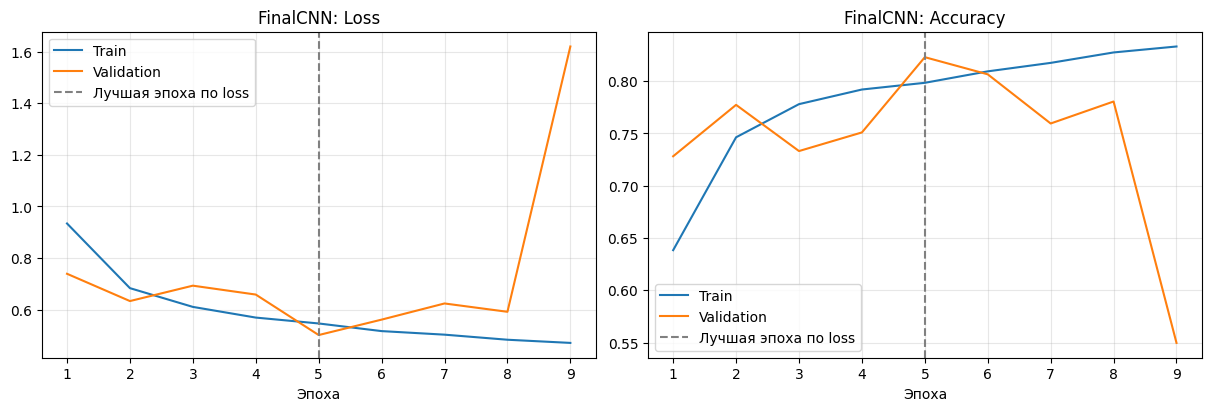

Графики: /content/drive/MyDrive/image-classification/models/final_cnn_curves.png


In [9]:
if history_final["val_loss"]:
    epochs = range(1, len(history_final["val_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for ax, train_key, val_key, title in zip(
        axes, ["train_loss", "train_acc"], ["val_loss", "val_acc"], ["Loss", "Accuracy"],
    ):
        ax.plot(epochs, history_final[train_key], label="Train")
        ax.plot(epochs, history_final[val_key], label="Validation")
        ax.axvline(best_epoch_final, linestyle="--", color="gray", label="Лучшая эпоха по loss")
        ax.set_title(f"FinalCNN: {title}")
        ax.set_xlabel("Эпоха")
        ax.legend()
        ax.grid(alpha=0.3)
    fig.savefig(plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Графики:", plot_path)
else:
    print("Графики появятся после обучения FinalCNN.")


## Сравнение с экспериментом 2

Используем известные итоги предыдущего запуска. Максимальная validation accuracy второго эксперимента отдельно не зафиксирована, поэтому оставим её без значения. Accuracy на лучшей эпохе относится к минимуму loss, а не обязательно к максимуму accuracy.

Сравниваем весь набор изменений FinalCNN; один запуск не позволяет выделить вклад каждого слоя.


In [10]:
experiment2 = {
    "val_loss": 0.4978,
    "accuracy_at_best_loss": 0.834,
    "max_val_accuracy": None,
    "best_epoch": 10,
    "parameters": simplecnn_parameters,
}
print(f"{'Модель':<16} {'Min val loss':>13} {'Acc при min loss':>18} {'Max val acc':>13} {'Эпоха':>7} {'Параметры':>12}")
print(
    f"{'CNN + аугментации':<16} {experiment2['val_loss']:>13.4f} "
    f"{experiment2['accuracy_at_best_loss']:>18.1%} {'нет данных':>13} "
    f"{experiment2['best_epoch']:>7} {experiment2['parameters']:>12,}"
)
if final_results is not None:
    final_loss = final_results["min_val_loss"]
    final_accuracy = final_results["accuracy_at_best_loss"]
    print(
        f"{'FinalCNN':<16} {final_loss:>13.4f} {final_accuracy:>18.1%} "
        f"{final_results['max_val_accuracy']:>13.1%} {final_results['best_epoch']:>7} {final_results['parameters']:>12,}"
    )
    print(f"\nРазница val loss (FinalCNN − эксперимент 2): {final_loss - experiment2['val_loss']:+.4f}")
    print(f"Разница accuracy на лучшей эпохе: {100 * (final_accuracy - experiment2['accuracy_at_best_loss']):+.1f} п.п.")
    if final_loss < experiment2["val_loss"]:
        print("В этом запуске FinalCNN дала меньший validation loss.")
    elif final_loss > experiment2["val_loss"]:
        print("В этом запуске FinalCNN не снизила validation loss относительно эксперимента 2.")
    else:
        print("Validation loss совпал с результатом эксперимента 2.")
else:
    print("Результаты FinalCNN пока недоступны; сравнение появится после обучения или загрузки метрик.")


Модель            Min val loss   Acc при min loss   Max val acc   Эпоха    Параметры
CNN + аугментации        0.4978              83.4%    нет данных      10    2,121,638
FinalCNN                0.5012              82.3%         82.3%       5      155,782

Разница val loss (FinalCNN − эксперимент 2): +0.0034
Разница accuracy на лучшей эпохе: -1.1 п.п.
В этом запуске FinalCNN не снизила validation loss относительно эксперимента 2.
